In [11]:
#imports
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression , Lasso , LassoCV , ElasticNetCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import  make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns


In [12]:
#reading file
base_path = Path.cwd().parent
df = pd.read_parquet(f"{base_path}/data/processed/clean_telemetry.parquet")

In [13]:
track = {"Rettifilo" : (130,185), "Roggia":(325,385) , "Lesmo":(405,530) , "Ascari" : (650 , 740) , "Parabolica" : (860,970)}
track_parts = []
for curve , (start , end) in track.items():
    curves = df["track_segment"].between(start , end)
    section = df[curves]
    mlData = section.groupby(["session" , "completedLaps"]).agg(min_speed = ("speedKmh" , min) , exit_speed=("speedKmh" , "last"),mean_speed=("speedKmh" , "mean"),mean_gas=("gas" , "mean") , mean_brake=("brake" , "mean"))
    mlData = mlData.add_prefix(f"{curve}_")
    track_parts.append(mlData)

monza = pd.concat(track_parts , axis=1)
print(monza)

                       Rettifilo_min_speed  Rettifilo_exit_speed  \
session completedLaps                                              
1       5                        64.864954            120.148296   
        6                        63.819803            131.560845   
        9                        52.487254            131.181325   
        12                       46.796174            128.613419   
        14                       63.439513            130.738285   
2       1                        45.883944            127.045503   
        5                        49.772368            126.236040   
        7                        49.682015            129.766464   
        8                        55.403060            133.633434   
        9                        52.975267            132.030350   
3       1                        53.325133            129.754855   
        2                        57.370324            130.630146   
        3                        52.025585      

In [14]:
X = monza
y = df.groupby(["session" , "completedLaps"])["cleanLaps"].first().round(3)
X_train  , X_test , y_train , y_test = train_test_split(X ,y , test_size=0.2 , random_state=42)
model_lr = LinearRegression()
model_lr.fit(X_train , y_train)
y_pred_lr = model_lr.predict(X_test)
mae_lr = mean_absolute_error(y_test , y_pred_lr)
r2_lr = r2_score(y_test , y_pred_lr)
cv_mae_rl = -cross_val_score(model_lr , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_lr , r2_lr , cv_mae_rl)

0.9959366357092299 0.734595734955745 3.9028616834702112


In [15]:
model_rf = RandomForestRegressor(random_state=42)
model_rf.fit(X_train , y_train)
y_pred_rf = model_rf.predict(X_test)
mae_rf = mean_absolute_error(y_test , y_pred_rf)
r2_rf = r2_score(y_test , y_pred_rf)
cv_mae_rf = -cross_val_score(model_rf , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_rf , r2_rf , cv_mae_rf)


1.5692100000000002 0.4307233627209559 0.9070574285714276


In [16]:
model_gb = GradientBoostingRegressor(random_state=42)
model_gb.fit(X_train , y_train)
y_pred_gb = model_gb.predict(X_test)
mae_gb = mean_absolute_error(y_test , y_pred_gb)
r2_gb = r2_score(y_test , y_pred_gb)
cv_mae_gb = -cross_val_score(model_gb , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
print(mae_gb , r2_gb , cv_mae_gb)


1.4287441252257946 0.5018702452198363 1.0202339708257209


In [17]:

model_l = make_pipeline(StandardScaler() , Lasso(alpha = 0.05))
model_l.fit(X_train , y_train)
y_pred_l = model_l.predict(X_test)
mae_l = mean_absolute_error(y_test , y_pred_l)
r2_l = r2_score(y_test , y_pred_l)
cv_mae_l = -cross_val_score(model_l , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
coef = model_l[-1].coef_
print(mae_l , r2_l , cv_mae_l)

1.180192330191527 0.7037680357329901 0.7404825155580619


In [18]:
model_l_cv = make_pipeline(StandardScaler() , LassoCV(alphas = np.linspace(0.01 , 0.1, 100) , cv=5 , random_state=42))
model_l_cv.fit(X_train , y_train)
y_pred_l_cv = model_l_cv.predict(X_test)
mae_l_cv = mean_absolute_error(y_test , y_pred_l_cv)
r2_l_cv = r2_score(y_test , y_pred_l_cv)
cv_mea_cv = -cross_val_score(model_l_cv , X , y ,cv=5 , scoring="neg_mean_absolute_error").mean()
coef_cv = model_l_cv[-1].coef_

In [19]:
model_e=make_pipeline(StandardScaler() , ElasticNetCV(alphas = np.linspace(0.01 , 0.1, 100) , cv=5 , random_state=42))
model_e.fit(X_train , y_train)
y_pred_e = model_e.predict(X_test)
mae_e = mean_absolute_error(y_test , y_pred_e)
r2_e = r2_score(y_test , y_pred_e)
cv_mea_e = -cross_val_score(model_e , X , y , cv=5 , scoring="neg_mean_absolute_error").mean()
coef_e = model_e[-1].coef_
best_alpha = model_e[-1].alpha_

               Model       MAE        R2    CV_MAE
0  Linear Regression  0.995937  0.734596  3.902862
1      Random Forest  1.569210  0.430723  0.907057
2  Gradient Boosting  1.428744  0.501870  1.020234
3              Lasso  1.180192  0.703768  0.740483
4            LassoCv  1.032375  0.734380  0.721807
5         ElasticNet  1.005517  0.754281  0.679233 0.023636363636363636


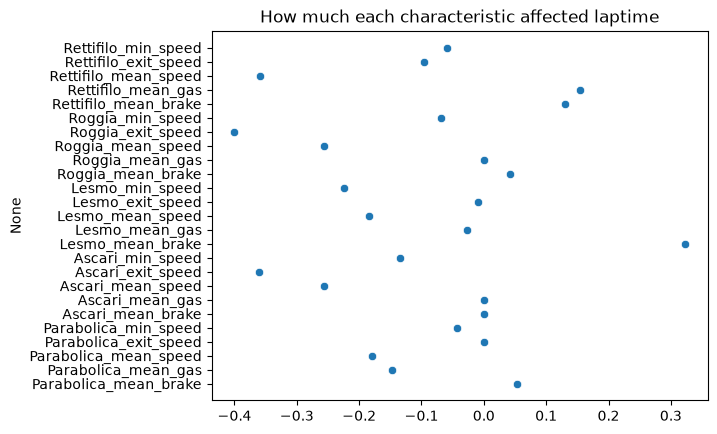

In [ ]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Gradient Boosting" , "Lasso" , "LassoCv" , "ElasticNet"],
    "MAE": [mae_lr, mae_rf, mae_gb , mae_l , mae_l_cv , mae_e],
    "R2": [r2_lr, r2_rf, r2_gb , r2_l , r2_l_cv , r2_e],
    "CV_MAE": [cv_mae_rl, cv_mae_rf, cv_mae_gb , cv_mae_l , cv_mea_cv , cv_mea_e],
})
sns.barplot(x=coef_e, y=X.columns )
print(results , best_alpha)
plt.title("How much each characteristic affected laptime")
plt.show()
